# Waste image classification with MobileNetV2 (corrected evaluation)
Fixes over the first notebook: fixed, disjoint, stratified train/val/test splits made from image paths (duplicate-aware), fresh ImageNet weights, frozen vs fine-tuned comparison on the same test set, macro-F1, latency, optional phone-photo test.
Run top to bottom (Runtime -> GPU).

In [ ]:
!pip install -q kagglehub
import os, random, hashlib, json, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import kagglehub
path = kagglehub.dataset_download("mostafaabla/garbage-classification")
DATA_DIR = None
for root, dirs, files in os.walk(path):
    if len(dirs) >= 10:
        DATA_DIR = root
        break
class_names = sorted(d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d)))
NUM_CLASSES = len(class_names)
print(DATA_DIR, NUM_CLASSES, class_names)

rows = []
for ci, c in enumerate(class_names):
    for f in os.listdir(os.path.join(DATA_DIR, c)):
        if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')):
            rows.append((os.path.join(DATA_DIR, c, f), ci, c))
df = pd.DataFrame(rows, columns=['path', 'label', 'class'])
print("Files found:", len(df))

Using Colab cache for faster access to the 'garbage-classification' dataset.
/kaggle/input/garbage-classification/garbage_classification 12 ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
Files found: 15515


In [ ]:
# 1) keep only readable images
def is_readable(p):
    try:
        tf.io.decode_image(tf.io.read_file(p), channels=3, expand_animations=False)
        return True
    except Exception:
        return False

df['ok'] = df['path'].map(is_readable)
print("Unreadable images removed:", int((~df['ok']).sum()))
df = df[df['ok']].drop(columns='ok').reset_index(drop=True)

# 2) exact-duplicate detection (byte-identical files). Near-duplicates are NOT caught.
def md5(p):
    with open(p, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()
df['md5'] = df['path'].map(md5)

g = df.groupby('md5')
dup_groups = g.filter(lambda x: len(x) > 1)
print("Readable images:", len(df))
print("Images that have an exact duplicate:", len(dup_groups), "| duplicate groups:", dup_groups['md5'].nunique())
cross = g['label'].nunique()
print("Duplicate groups with conflicting labels:", int((cross > 1).sum()))
print(df['class'].value_counts())

Unreadable images removed: 0
Readable images: 15515
Images that have an exact duplicate: 37 | duplicate groups: 18
Duplicate groups with conflicting labels: 3
class
clothes        5325
shoes          1977
paper          1050
biological      985
battery         945
cardboard       891
plastic         865
white-glass     775
metal           769
trash           697
green-glass     629
brown-glass     607
Name: count, dtype: int64


In [ ]:
# 3) fixed, stratified, group-aware split (~80/10/10); identical files always stay in the same partition
groups = df['md5'].values
y = df['label'].values

sgkf = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED)
rest_idx, test_idx = next(sgkf.split(df, y, groups))
rest = df.iloc[rest_idx].reset_index(drop=True)
test_df = df.iloc[test_idx].reset_index(drop=True)

sgkf2 = StratifiedGroupKFold(n_splits=9, shuffle=True, random_state=SEED)
tr_idx, va_idx = next(sgkf2.split(rest, rest['label'].values, rest['md5'].values))
train_df = rest.iloc[tr_idx].reset_index(drop=True)
val_df = rest.iloc[va_idx].reset_index(drop=True)

# leakage checks
assert not set(train_df.path) & set(val_df.path)
assert not set(train_df.path) & set(test_df.path)
assert not set(val_df.path) & set(test_df.path)
assert not set(train_df.md5) & set(val_df.md5)
assert not set(train_df.md5) & set(test_df.md5)
assert not set(val_df.md5) & set(test_df.md5)

print("train/val/test:", len(train_df), len(val_df), len(test_df))
counts = pd.DataFrame({
    'train': train_df['class'].value_counts(),
    'val': val_df['class'].value_counts(),
    'test': test_df['class'].value_counts()}).fillna(0).astype(int)
print(counts)   # use this table in the paper

os.makedirs('outputs', exist_ok=True)
train_df.to_csv('outputs/train_split.csv', index=False)
val_df.to_csv('outputs/val_split.csv', index=False)
test_df.to_csv('outputs/test_split.csv', index=False)
json.dump(class_names, open('outputs/class_names.json', 'w'))
counts.to_csv('outputs/split_counts.csv')

train/val/test: 12412 1550 1553
             train  val  test
class                        
battery        760   99    86
biological     794  106    85
brown-glass    489   62    56
cardboard      724   78    89
clothes       4267  527   531
green-glass    480   75    74
metal          604   74    91
paper          835  104   111
plastic        702   85    78
shoes         1570  197   210
trash          569   73    55
white-glass    618   70    87


In [ ]:
IMG_SIZE = (224, 224)
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE

def load(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    img.set_shape((224, 224, 3))
    return img, label

def make_ds(d, training=False):
    ds = tf.data.Dataset.from_tensor_slices((d['path'].values, d['label'].values))
    if training:
        ds = ds.shuffle(len(d), seed=SEED, reshuffle_each_iteration=True)   # only the TRAIN set is reshuffled
    return ds.map(load, num_parallel_calls=AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)

train_ds = make_ds(train_df, True)
val_ds = make_ds(val_df)     # fixed order, so predictions line up with val_df
test_ds = make_ds(test_df)   # fixed order, so predictions line up with test_df

In [ ]:
def build_model():
    aug = tf.keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),
        layers.RandomContrast(0.1),
    ], name="data_augmentation")
    base = tf.keras.applications.MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights="imagenet")
    base.trainable = False
    inp = layers.Input(shape=(224, 224, 3))
    x = aug(inp)
    x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
    x = base(x, training=False)          # keeps BatchNorm in inference mode, also during fine-tuning
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return models.Model(inp, out), base

def evaluate(model, d, ds, name):
    probs = model.predict(ds, verbose=0)
    yp = probs.argmax(1); yt = d['label'].values
    res = dict(model=name,
               accuracy=accuracy_score(yt, yp),
               macro_f1=f1_score(yt, yp, average='macro'),
               weighted_f1=f1_score(yt, yp, average='weighted'))
    return res, yp

def new_callbacks():
    return [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)]

tf.keras.backend.clear_session()
model, base_model = build_model()      # fresh ImageNet weights, nothing carried over from the old run

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
# Stage 1: frozen backbone
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h1 = model.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=new_callbacks())

res_frozen_val, _ = evaluate(model, val_df, val_ds, "Frozen MobileNetV2")
res_frozen_test, pred_frozen = evaluate(model, test_df, test_ds, "Frozen MobileNetV2")
print("frozen  val:", res_frozen_val)
print("frozen test:", res_frozen_test)
model.save_weights("outputs/frozen.weights.h5")

Epoch 1/10
388/388 ━━━━━━━━━━━━━━━━━━━━ 35s 65ms/step - accuracy: 0.8188 - loss: 0.6053 - val_accuracy: 0.9335 - val_loss: 0.2394
Epoch 2/10
388/388 ━━━━━━━━━━━━━━━━━━━━ 35s 62ms/step - accuracy: 0.9069 - loss: 0.3004 - val_accuracy: 0.9426 - val_loss: 0.1995
Epoch 3/10
388/388 ━━━━━━━━━━━━━━━━━━━━ 41s 61ms/step - accuracy: 0.9141 - loss: 0.2601 - val_accuracy: 0.9406 - val_loss: 0.1862
Epoch 4/10
388/388 ━━━━━━━━━━━━━━━━━━━━ 24s 61ms/step - accuracy: 0.9250 - loss: 0.2264 - val_accuracy: 0.9400 - val_loss: 0.1844
Epoch 5/10
388/388 ━━━━━━━━━━━━━━━━━━━━ 24s 62ms/step - accuracy: 0.9302 - loss: 0.2136 - val_accuracy: 0.9400 - val_loss: 0.1757
Epoch 6/10
388/388 ━━━━━━━━━━━━━━━━━━━━ 24s 62ms/step - accuracy: 0.9308 - loss: 0.2080 - val_accuracy: 0.9439 - val_loss: 0.1726
Epoch 7/10
388/388 ━━━━━━━━━━━━━━━━━━━━ 24s 62ms/step - accuracy: 0.9337 - loss: 0.2001 - val_accuracy: 0.9413 - val_loss: 0.1792
Epoch 8/10
388/388 ━━━━━━━━━━━━━━━━━━━━ 24s 62ms/step - accuracy: 0.9380 - loss: 0.1902 - 

In [ ]:
# Stage 2: fine-tune from layer 100 onward
base_model.trainable = True
for layer in base_model.layers[:100]:
    layer.trainable = False
model.compile(optimizer=tf.keras.optimizers.Adam(1e-5), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
FT_EPOCHS = 5     # raise (e.g. 10) if you have time; early stopping will cut it short if needed
h2 = model.fit(train_ds, validation_data=val_ds, epochs=FT_EPOCHS, callbacks=new_callbacks())

res_ft_val, _ = evaluate(model, val_df, val_ds, "Fine-tuned MobileNetV2")
res_ft_test, pred_ft = evaluate(model, test_df, test_ds, "Fine-tuned MobileNetV2")
print("fine-tuned  val:", res_ft_val)
print("fine-tuned test:", res_ft_test)

Epoch 1/5
388/388 ━━━━━━━━━━━━━━━━━━━━ 52s 104ms/step - accuracy: 0.8867 - loss: 0.3586 - val_accuracy: 0.9503 - val_loss: 0.1705
Epoch 2/5
388/388 ━━━━━━━━━━━━━━━━━━━━ 39s 100ms/step - accuracy: 0.9148 - loss: 0.2747 - val_accuracy: 0.9523 - val_loss: 0.1694
Epoch 3/5
388/388 ━━━━━━━━━━━━━━━━━━━━ 43s 104ms/step - accuracy: 0.9228 - loss: 0.2346 - val_accuracy: 0.9561 - val_loss: 0.1677
Epoch 4/5
388/388 ━━━━━━━━━━━━━━━━━━━━ 39s 101ms/step - accuracy: 0.9316 - loss: 0.2165 - val_accuracy: 0.9574 - val_loss: 0.1568
Epoch 5/5
388/388 ━━━━━━━━━━━━━━━━━━━━ 40s 102ms/step - accuracy: 0.9385 - loss: 0.1871 - val_accuracy: 0.9581 - val_loss: 0.1524
fine-tuned  val: {'model': 'Fine-tuned MobileNetV2', 'accuracy': 0.9580645161290322, 'macro_f1': 0.9413955392207759, 'weighted_f1': 0.9581249035814979}
fine-tuned test: {'model': 'Fine-tuned MobileNetV2', 'accuracy': 0.9420476497102382, 'macro_f1': 0.9194160598586797, 'weighted_f1': 0.9420930882898372}


                 model  accuracy  macro_f1  weighted_f1 split
    Frozen MobileNetV2    0.9439    0.9203       0.9438   val
Fine-tuned MobileNetV2    0.9581    0.9414       0.9581   val
    Frozen MobileNetV2    0.9356    0.9119       0.9357  test
Fine-tuned MobileNetV2    0.9420    0.9194       0.9421  test


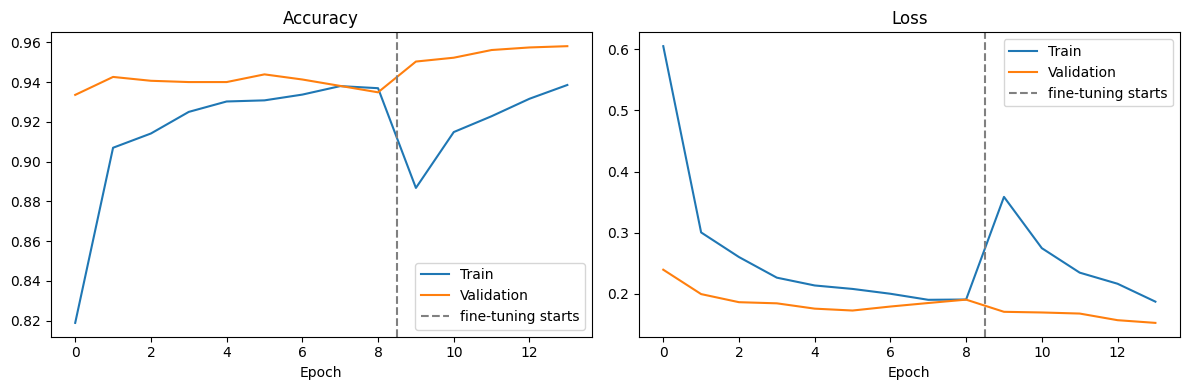

In [ ]:
# Comparison table (test set) - selection was done on validation macro-F1
table = pd.DataFrame([res_frozen_val | {'split': 'val'}, res_ft_val | {'split': 'val'},
                      res_frozen_test | {'split': 'test'}, res_ft_test | {'split': 'test'}])
print(table.round(4).to_string(index=False))
table.to_csv('outputs/results_table.csv', index=False)

# learning curves
acc = h1.history['accuracy'] + h2.history['accuracy']
vacc = h1.history['val_accuracy'] + h2.history['val_accuracy']
loss = h1.history['loss'] + h2.history['loss']
vloss = h1.history['val_loss'] + h2.history['val_loss']
ep1 = len(h1.history['loss'])
plt.figure(figsize=(12, 4))
for i, (a, b, t) in enumerate([(acc, vacc, 'Accuracy'), (loss, vloss, 'Loss')]):
    plt.subplot(1, 2, i + 1)
    plt.plot(a, label='Train'); plt.plot(b, label='Validation')
    plt.axvline(ep1 - 0.5, ls='--', c='gray', label='fine-tuning starts')
    plt.title(t); plt.xlabel('Epoch'); plt.legend()
plt.tight_layout(); plt.savefig('outputs/learning_curves.png', dpi=200); plt.show()

              precision    recall  f1-score   support

     battery     0.9111    0.9535    0.9318        86
  biological     0.9770    1.0000    0.9884        85
 brown-glass     0.9444    0.9107    0.9273        56
   cardboard     0.9630    0.8764    0.9176        89
     clothes     0.9924    0.9849    0.9887       531
 green-glass     0.9459    0.9459    0.9459        74
       metal     0.8173    0.9341    0.8718        91
       paper     0.9143    0.8649    0.8889       111
     plastic     0.7662    0.7564    0.7613        78
       shoes     0.9671    0.9810    0.9740       210
       trash     0.9818    0.9818    0.9818        55
 white-glass     0.8605    0.8506    0.8555        87

    accuracy                         0.9420      1553
   macro avg     0.9201    0.9200    0.9194      1553
weighted avg     0.9430    0.9420    0.9421      1553



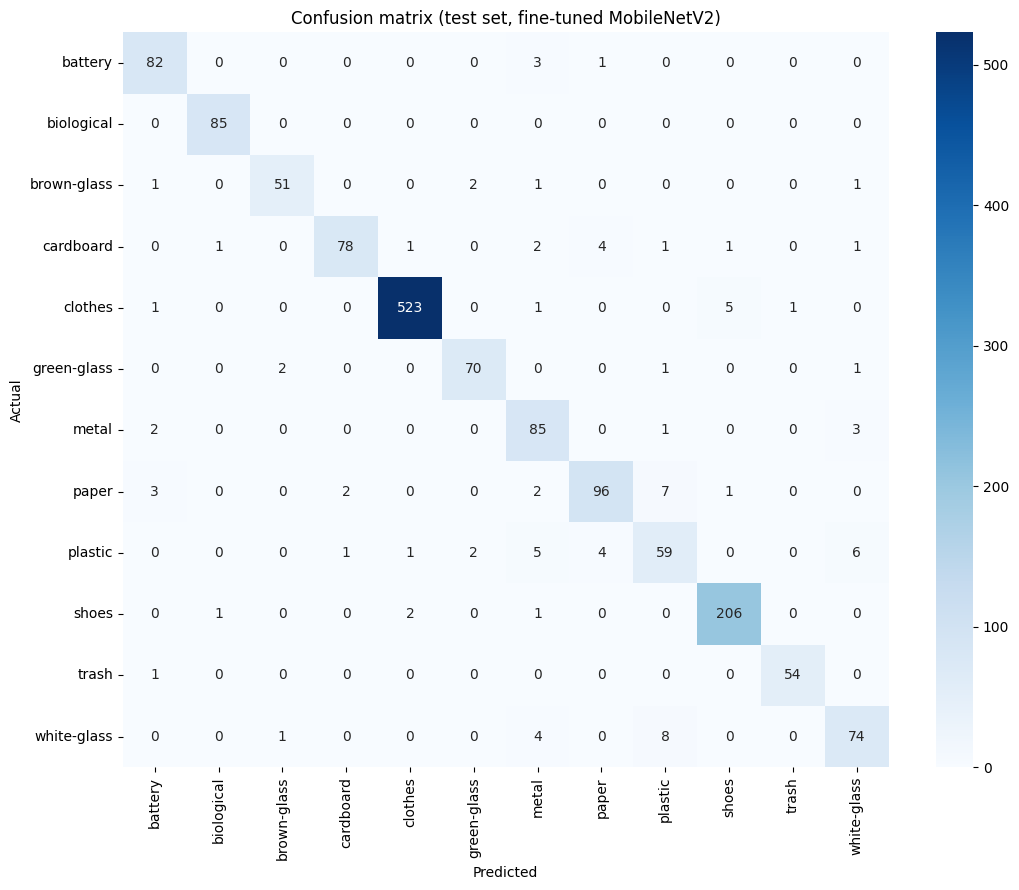

white-glass -> plastic: 8
paper -> plastic: 7
plastic -> white-glass: 6
clothes -> shoes: 5
plastic -> metal: 5


In [ ]:
# Final model = fine-tuned (compare on validation numbers printed above before you claim this)
yt = test_df['label'].values
print(classification_report(yt, pred_ft, labels=list(range(NUM_CLASSES)), target_names=class_names, digits=4))

cm = confusion_matrix(yt, pred_ft, labels=list(range(NUM_CLASSES)))
plt.figure(figsize=(11, 9))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Confusion matrix (test set, fine-tuned MobileNetV2)')
plt.tight_layout(); plt.savefig('outputs/confusion_matrix.png', dpi=200); plt.show()

# most frequent confusions
cm_off = cm.copy(); np.fill_diagonal(cm_off, 0)
top = np.dstack(np.unravel_index(np.argsort(-cm_off.ravel())[:5], cm_off.shape))[0]
for a, b in top:
    print(f"{class_names[a]} -> {class_names[b]}: {cm_off[a, b]}")

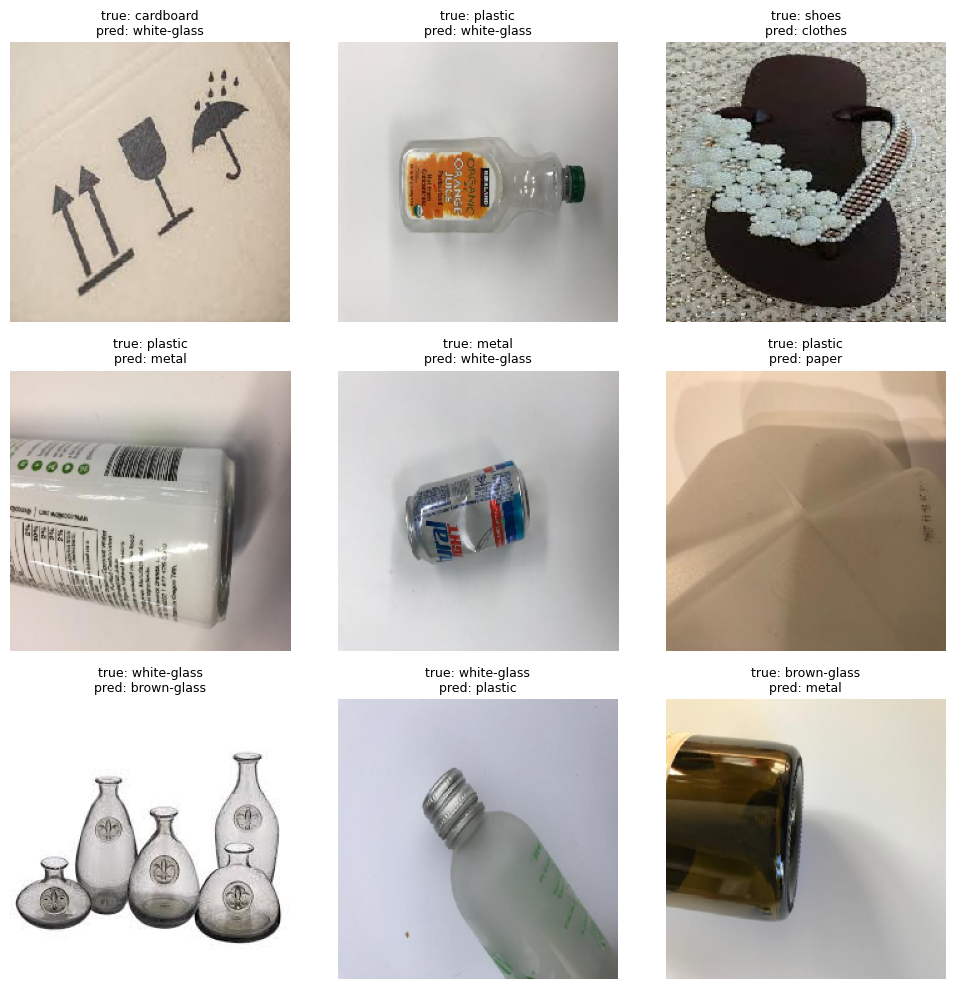

90 wrong predictions in total


In [ ]:
# Wrong predictions:
rng = np.random.default_rng(42)
wrong_all = np.where(pred_ft != yt)[0]
wrong = rng.choice(wrong_all, size=9, replace=False)
plt.figure(figsize=(10, 10))
for k, i in enumerate(wrong):
    img = tf.keras.utils.load_img(test_df.path[i], target_size=IMG_SIZE)
    plt.subplot(3, 3, k + 1); plt.imshow(img); plt.axis('off')
    plt.title(f"true: {class_names[yt[i]]}\npred: {class_names[pred_ft[i]]}", fontsize=9)
plt.tight_layout(); plt.savefig('outputs/errors.png', dpi=200); plt.show()
print(len(wrong_all), "wrong predictions in total")

In [ ]:
# Model-only inference latency (batch size 1)
import subprocess
print("Hardware:", subprocess.run("nvidia-smi --query-gpu=name --format=csv,noheader", shell=True, capture_output=True, text=True).stdout.strip())
x = (np.random.rand(1, 224, 224, 3) * 255).astype('float32')
for _ in range(20):
    model(x, training=False)
ts = []
for _ in range(200):
    t0 = time.perf_counter(); _ = model(x, training=False).numpy(); ts.append((time.perf_counter() - t0) * 1000)
print(f"median {np.median(ts):.1f} ms | p95 {np.percentile(ts, 95):.1f} ms (model only, no image loading)")

Hardware: Tesla T4
median 160.2 ms | p95 176.6 ms (model only, no image loading)


In [ ]:
@tf.function
def infer(x):
    return model(x, training=False)
x = tf.constant((np.random.rand(1, 224, 224, 3) * 255).astype('float32'))
for _ in range(20):
    infer(x).numpy()
ts = []
for _ in range(200):
    t0 = time.perf_counter(); infer(x).numpy(); ts.append((time.perf_counter() - t0) * 1000)
print(f"median {np.median(ts):.1f} ms | p95 {np.percentile(ts, 95):.1f} ms (compiled, batch 1, Tesla T4, model only)")

median 5.2 ms | p95 6.4 ms (compiled, batch 1, Tesla T4, model only)


In [ ]:
# OPTIONAL: your own phone photos. Put them as phone_photos/<class_name>/xxx.jpg (zip + upload to Colab, then unzip).
# Never tune on these. Report the number of distinct objects per class.
import glob
rows = []
for ci, c in enumerate(class_names):
    for p in glob.glob(f"phone_photos/{c}/*"):
        rows.append((p, ci))
if rows:
    pdf = pd.DataFrame(rows, columns=['path', 'label'])
    pds = make_ds(pdf)
    probs = model.predict(pds, verbose=0); pp = probs.argmax(1)
    print("Phone photos:", len(pdf), "| accuracy:", round(accuracy_score(pdf.label, pp), 4))
    print(classification_report(pdf.label, pp, labels=sorted(pdf.label.unique()),
          target_names=[class_names[i] for i in sorted(pdf.label.unique())], digits=3, zero_division=0))
else:
    print("No phone_photos folder found - skip.")

No phone_photos folder found - skip.


In [ ]:
model.save("outputs/waste_classifier_mobilenetv2_12class.keras")
print("Saved. Download the 'outputs' folder (CSV splits, figures, results table) for the paper / GitHub.")

Saved. Download the 'outputs' folder (CSV splits, figures, results table) for the paper / GitHub.


In [ ]:
!git clone -q https://github.com/pedropro/TACO.git
import json, random, requests
from collections import Counter

ann = json.load(open('TACO/data/annotations.json'))
cnt = Counter(a['image_id'] for a in ann['annotations'])
cands = [im for im in ann['images'] if cnt[im['id']] >= 5]
print(len(cands), "images with >=5 annotated objects")

random.seed(42)
pick = random.sample(cands, min(40, len(cands)))
os.makedirs('piles', exist_ok=True)
saved = 0
for im in pick:
    url = im.get('flickr_640_url') or im.get('flickr_url')
    try:
        r = requests.get(url, timeout=15)
        if r.status_code == 200 and len(r.content) > 5000:
            open(f"piles/taco_{im['id']}.jpg", 'wb').write(r.content)
            saved += 1
    except Exception:
        pass
    if saved >= 25:
        break
print("saved", saved, "photos to piles/")

254 images with >=5 annotated objects
saved 25 photos to piles/


In [ ]:
import glob
from PIL import Image
G = 3
os.makedirs('tiles', exist_ok=True)
trows = []
for p in sorted(glob.glob('piles/*')):
    im = Image.open(p).convert('RGB')
    w, h = im.size
    base = os.path.splitext(os.path.basename(p))[0]
    for r in range(G):
        for c in range(G):
            tile = im.crop((c * w // G, r * h // G, (c + 1) * w // G, (r + 1) * h // G))
            tp = f'tiles/{base}_r{r}c{c}.jpg'
            tile.save(tp)
            trows.append((base, tp, ''))
pd.DataFrame(trows, columns=['photo', 'tile_path', 'label']).to_csv('tile_labels_TEMPLATE.csv', index=False)
print(len(trows), "tiles written. Fill tile_labels_TEMPLATE.csv, save as tile_labels.csv")

225 tiles written. Fill tile_labels_TEMPLATE.csv, save as tile_labels.csv


In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output
T = pd.read_csv('tile_labels_TEMPLATE.csv')
T['label'] = T['label'].astype('object')
opts = class_names + ['mixed', 'background']
state = {'i': 0}
out = widgets.Output()

def show():
    with out:
        clear_output(wait=True)
        i = state['i']
        if i >= len(T):
            T.to_csv('tile_labels.csv', index=False)
            print("Done. Saved tile_labels.csv"); return
        plt.figure(figsize=(4, 4)); plt.imshow(Image.open(T.tile_path[i])); plt.axis('off')
        plt.title(f"{i+1}/{len(T)}  {T.photo[i]}"); plt.show()

def pick(lbl):
    def f(_):
        T.loc[state['i'], 'label'] = lbl
        state['i'] += 1
        if state['i'] % 10 == 0:
            T.to_csv('tile_labels_partial.csv', index=False)
        show()
    return f

def back(_):
    state['i'] = max(0, state['i'] - 1); show()

btns = []
for o in opts:
    b = widgets.Button(description=o, layout=widgets.Layout(width='110px'))
    b.on_click(pick(o)); btns.append(b)
bb = widgets.Button(description='back', button_style='warning'); bb.on_click(back)
display(widgets.HBox(btns[:5]), widgets.HBox(btns[5:10]), widgets.HBox(btns[10:] + [bb]), out)
show()

Output()

In [ ]:
lab = pd.read_csv('tile_labels.csv').dropna(subset=['label'])
lab['label'] = lab['label'].str.strip().str.lower()
name2id = {n: i for i, n in enumerate(class_names)}
valid = lab[lab['label'].isin(name2id)].copy()
other = lab[~lab['label'].isin(name2id)].copy()
valid['y'] = valid['label'].map(name2id)
print("Dominant-material tiles:", len(valid), "| mixed/background:", len(other), "| photos:", lab['photo'].nunique())

def predict_tiles(df_tiles):
    tmp = pd.DataFrame({'path': df_tiles['tile_path'].values, 'label': np.zeros(len(df_tiles), dtype=int)})
    pr = model.predict(make_ds(tmp), verbose=0)
    return pr.argmax(1), pr.max(1)

valid['pred'], valid['conf'] = predict_tiles(valid)
print("Tile accuracy:", round(accuracy_score(valid['y'], valid['pred']), 4),
      "| single-item test accuracy:", round(res_ft_test['accuracy'], 4))
print("Mean softmax score when correct:", round(valid.loc[valid.pred == valid.y, 'conf'].mean(), 3),
      "| when wrong:", round(valid.loc[valid.pred != valid.y, 'conf'].mean(), 3))

if len(other):
    _, oconf = predict_tiles(other)
    print("Mixed/background tiles, mean softmax score:", round(oconf.mean(), 3))

errs = []
for ph, g in valid.groupby('photo'):
    t = g['y'].value_counts(normalize=True).reindex(range(NUM_CLASSES), fill_value=0)
    q = g['pred'].value_counts(normalize=True).reindex(range(NUM_CLASSES), fill_value=0)
    errs.append(0.5 * np.abs(t - q).sum())
print("Mean composition error per photo:", round(np.mean(errs), 3), "over", len(errs), "photos")

present = sorted(valid['y'].unique())
print(classification_report(valid['y'], valid['pred'], labels=present,
      target_names=[class_names[i] for i in present], digits=3, zero_division=0))
valid.to_csv('outputs/pile_tile_results.csv', index=False)

Dominant-material tiles: 37 | mixed/background: 188 | photos: 25
Tile accuracy: 0.4865 | single-item test accuracy: 0.942
Mean softmax score when correct: 0.782 | when wrong: 0.582
Mixed/background tiles, mean softmax score: 0.665
Mean composition error per photo: 0.635 over 15 photos
              precision    recall  f1-score   support

  biological      0.750     0.857     0.800         7
     clothes      1.000     0.500     0.667         2
       metal      0.600     0.375     0.462         8
       paper      1.000     0.333     0.500         6
     plastic      0.667     0.500     0.571        12
       trash      0.000     0.000     0.000         2

   micro avg      0.667     0.486     0.562        37
   macro avg      0.669     0.428     0.500        37
weighted avg      0.704     0.486     0.554        37



In [ ]:
bg_only = lab[lab['label'] == 'background']
mx = lab[lab['label'] == 'mixed']
_, c_bg = predict_tiles(bg_only)
_, c_mx = predict_tiles(mx)
print("background tiles:", len(bg_only), "| mixed tiles:", len(mx), "| class tiles:", len(valid))
rows = []
for t in [0.5, 0.7, 0.9]:
    kept = valid[valid.conf >= t]
    rows.append(dict(threshold=t,
                     background_accepted=round(float((c_bg >= t).mean()), 2),
                     mixed_accepted=round(float((c_mx >= t).mean()), 2),
                     class_tiles_kept=round(len(kept) / len(valid), 2),
                     accuracy_of_kept=round(float((kept.pred == kept.y).mean()), 3) if len(kept) else None))
print(pd.DataFrame(rows).to_string(index=False))

from statsmodels.stats.proportion import proportion_confint
k = int((valid.pred == valid.y).sum()); n = len(valid)
print("tile accuracy", k, "of", n, "| Wilson 95% CI:", np.round(proportion_confint(k, n, method='wilson'), 3))

background tiles: 175 | mixed tiles: 13 | class tiles: 37
 threshold  background_accepted  mixed_accepted  class_tiles_kept  accuracy_of_kept
       0.5                 0.73            0.69              0.70             0.538
       0.7                 0.45            0.31              0.43             0.750
       0.9                 0.23            0.08              0.24             0.889
tile accuracy 18 of 37 | Wilson 95% CI: [0.334 0.641]


In [ ]:
bg = lab[~lab['label'].isin(name2id)]
_, bconf = predict_tiles(bg)
print("no-waste / mixed tiles:", len(bg))
for t in [0.5, 0.7, 0.9]:
    print(f"predicted as a waste class with score >= {t}: {(bconf >= t).mean():.2f}")

no-waste / mixed tiles: 188
predicted as a waste class with score >= 0.5: 0.72
predicted as a waste class with score >= 0.7: 0.44
predicted as a waste class with score >= 0.9: 0.22


In [ ]:
from sklearn.metrics import roc_auc_score
pt = model.predict(test_ds, verbose=0)
corr = (pt.argmax(1) == test_df['label'].values)
print("AUROC correct vs wrong (test set):", round(roc_auc_score(corr, pt.max(1)), 3))
yy = np.r_[np.ones(len(valid)), np.zeros(len(c_bg))]
ss = np.r_[valid['conf'].values, c_bg]
print("AUROC class tiles vs background tiles:", round(roc_auc_score(yy, ss), 3))

AUROC correct vs wrong (test set): 0.922
AUROC class tiles vs background tiles: 0.52


In [ ]:
!pip install -q imagehash
import imagehash
from PIL import Image
def h64(p):
    return int(str(imagehash.phash(Image.open(p).convert('RGB'))), 16)
Htr = np.array([h64(p) for p in train_df['path']], dtype=np.uint64)
Hte = np.array([h64(p) for p in test_df['path']], dtype=np.uint64)
LUT = np.array([bin(i).count('1') for i in range(256)], dtype=np.int32)
def popcount(x):
    c = np.zeros(x.shape, dtype=np.int32)
    for s in range(0, 64, 8):
        c += LUT[((x >> np.uint64(s)) & np.uint64(255)).astype(np.int64)]
    return c
near = 0
for i in range(0, len(Hte), 100):
    dist = popcount(Hte[i:i + 100, None] ^ Htr[None, :])
    near += int((dist.min(1) <= 4).sum())
print("test images with a train image within Hamming distance 4:", near, "of", len(Hte))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 11.1 MB/s eta 0:00:00
test images with a train image within Hamming distance 4: 23 of 1553
